# compare the methods

| name | call | source |
|---|---|---|
| R | `predict(fit, newdata, se = TRUE)` | installed R |
| Nov 6 patch | `predict(fit, newdata, se = TRUE, cache = TRUE)` | `shared/reference-nov6/` |
| loesslin | `loesslin::predict_se(fit, newdata)` | this package |

one section per experiment: R against the experiment's builds, timed with atime. every function is from `shared/harness/`.

run first: `R CMD INSTALL .` and the five `experiments/exp_*/run.R`. needs `atime` and `IRkernel`.

In [1]:
repo <- normalizePath("..")
for (file in c("common.R", "speed.R", "memory.R", "tied.R")) source(file.path(repo, "shared", "harness", file))
library(atime); library(ggplot2); library(directlabels)
options(repr.plot.width = 9, repr.plot.height = 4.5, repr.plot.res = 200)
asset <- function(name, kind) file.path(repo, "docs", "assets", paste0(name, "-", kind))

# a library an experiment built
built <- function(experiment, ..., so = "loessfactorpredict.so")
  load_loess(file.path(repo, "experiments", experiment, ".intermediates", ...), so)

# plot an atime result and save it for the README
keep <- function(result, name) { picture <- plot(result); ggsave(asset(name, "atime.png"), picture, width = 9, height = 4.5, dpi = 110); picture }

nov6      <- built("exp_000_baseline_prototype", "reference-nov6", so = "loesssent.so")
prototype <- built("exp_000_baseline_prototype", "src")

## exp_000: the prototype

Toby's setup (tdhock/atime#135). R stops from N = 46,337.

kilobytes counts R's allocator only. it misses the `R_Calloc` workspace of R: 20 GB at N = 45,000.

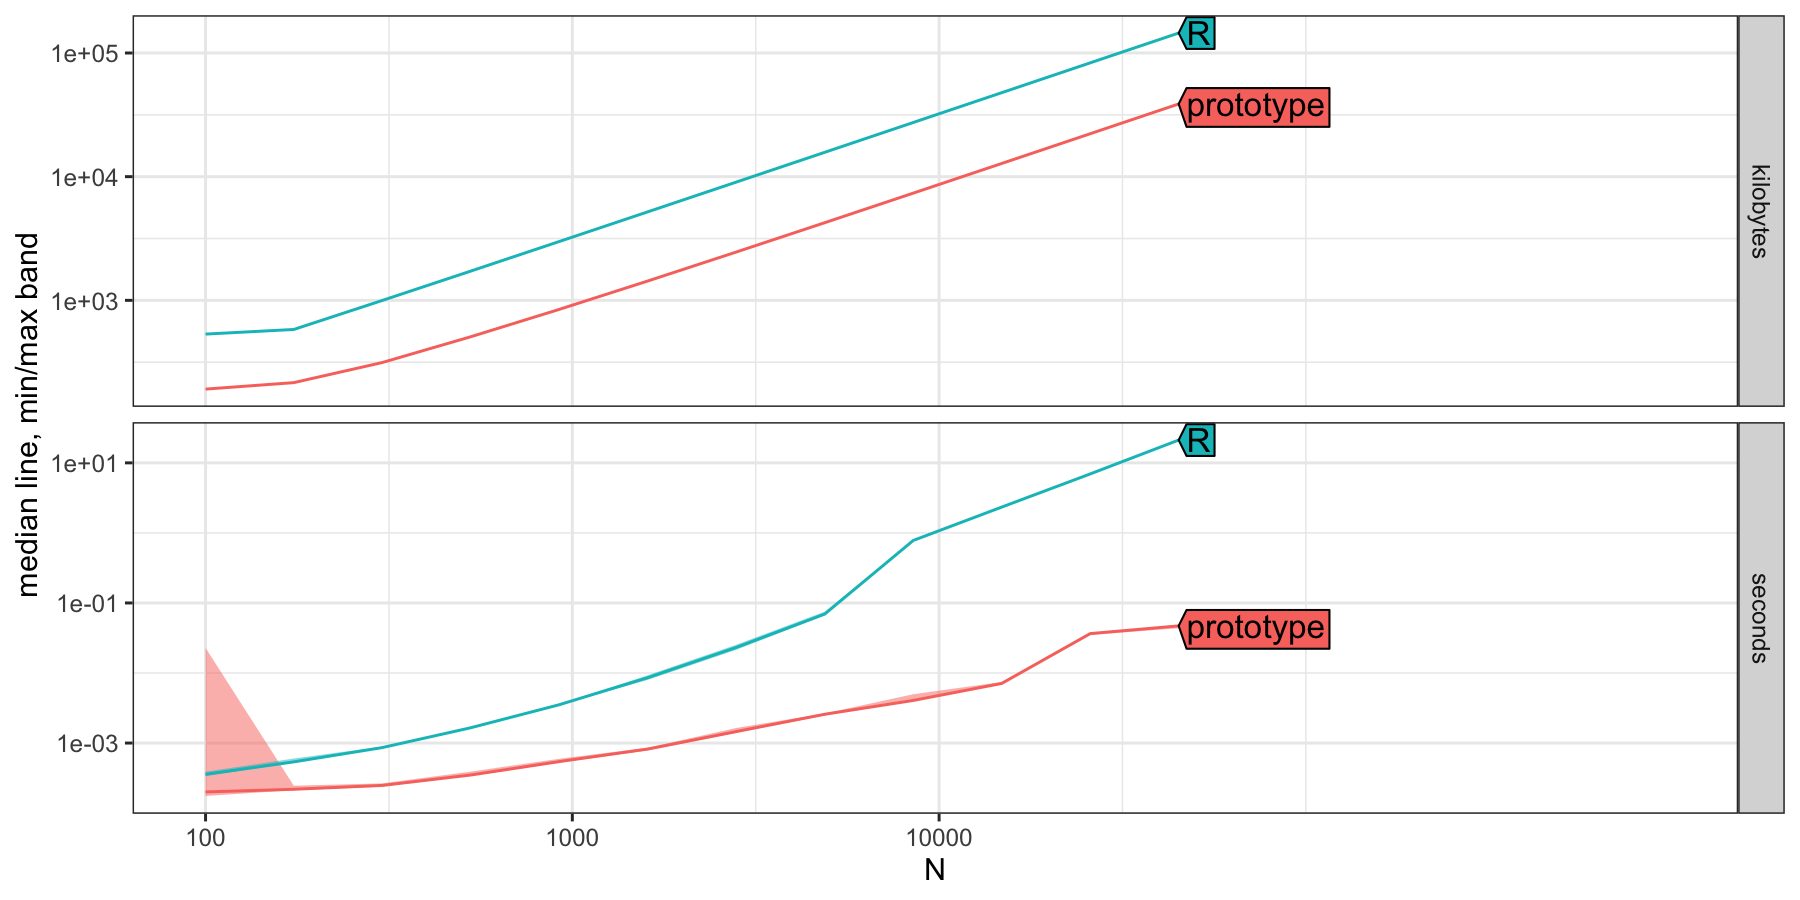

In [2]:
toby <- atime(
  N = as.integer(10^seq(2, log10(45000), length.out = 12)), setup = data <- toby_data(N),
  seconds.limit = 30, times = 3, check = TRUE,
  R = predict(data$fit, data$nd, se = TRUE),
  prototype = prototype$predict.loess(data$fit, data$nd, se = TRUE))
keep(toby, "exp_000")

## exp_001: eight reductions, each alone

each build is the prototype plus one patch. `single_plan_path` is the one dropped. atime stops R once a call passes 1 second.

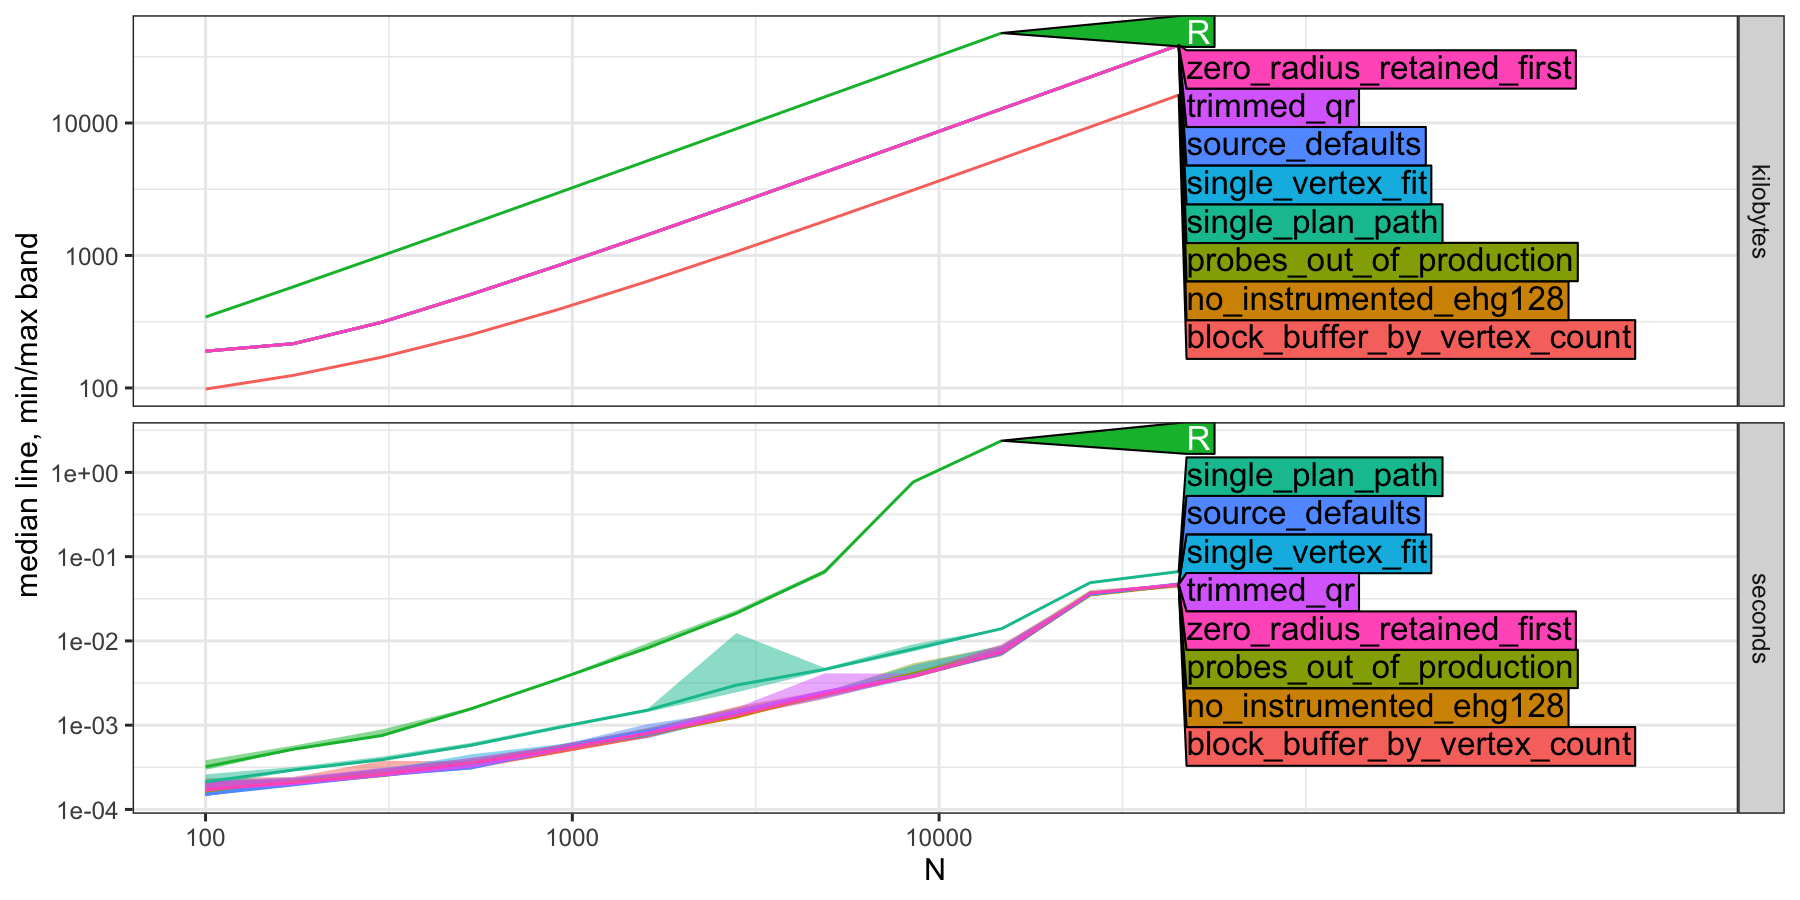

In [3]:
variants <- read.csv(file.path(repo, "experiments", "exp_001_reductions", "src", "variants.csv"))$name
builds <- sapply(variants, function(name) built("exp_001_reductions", name, "src"), simplify = FALSE)
reductions <- atime(
  N = as.integer(10^seq(2, log10(45000), length.out = 12)), setup = data <- toby_data(N),
  seconds.limit = 1, times = 5, check = TRUE,
  expr.list = c(list(R = quote(predict(data$fit, data$nd, se = TRUE))),
    lapply(builds, function(build) substitute(build$predict.loess(data$fit, data$nd, se = TRUE), list(build = build)))))
keep(reductions, "exp_001")

## exp_002: worst case

half of x tied at one point, so one vertex has radius zero. R's `predict` stops with an error on this fit, so the native entry is timed, R's own too. the cap is the bytes of vertex fits kept.

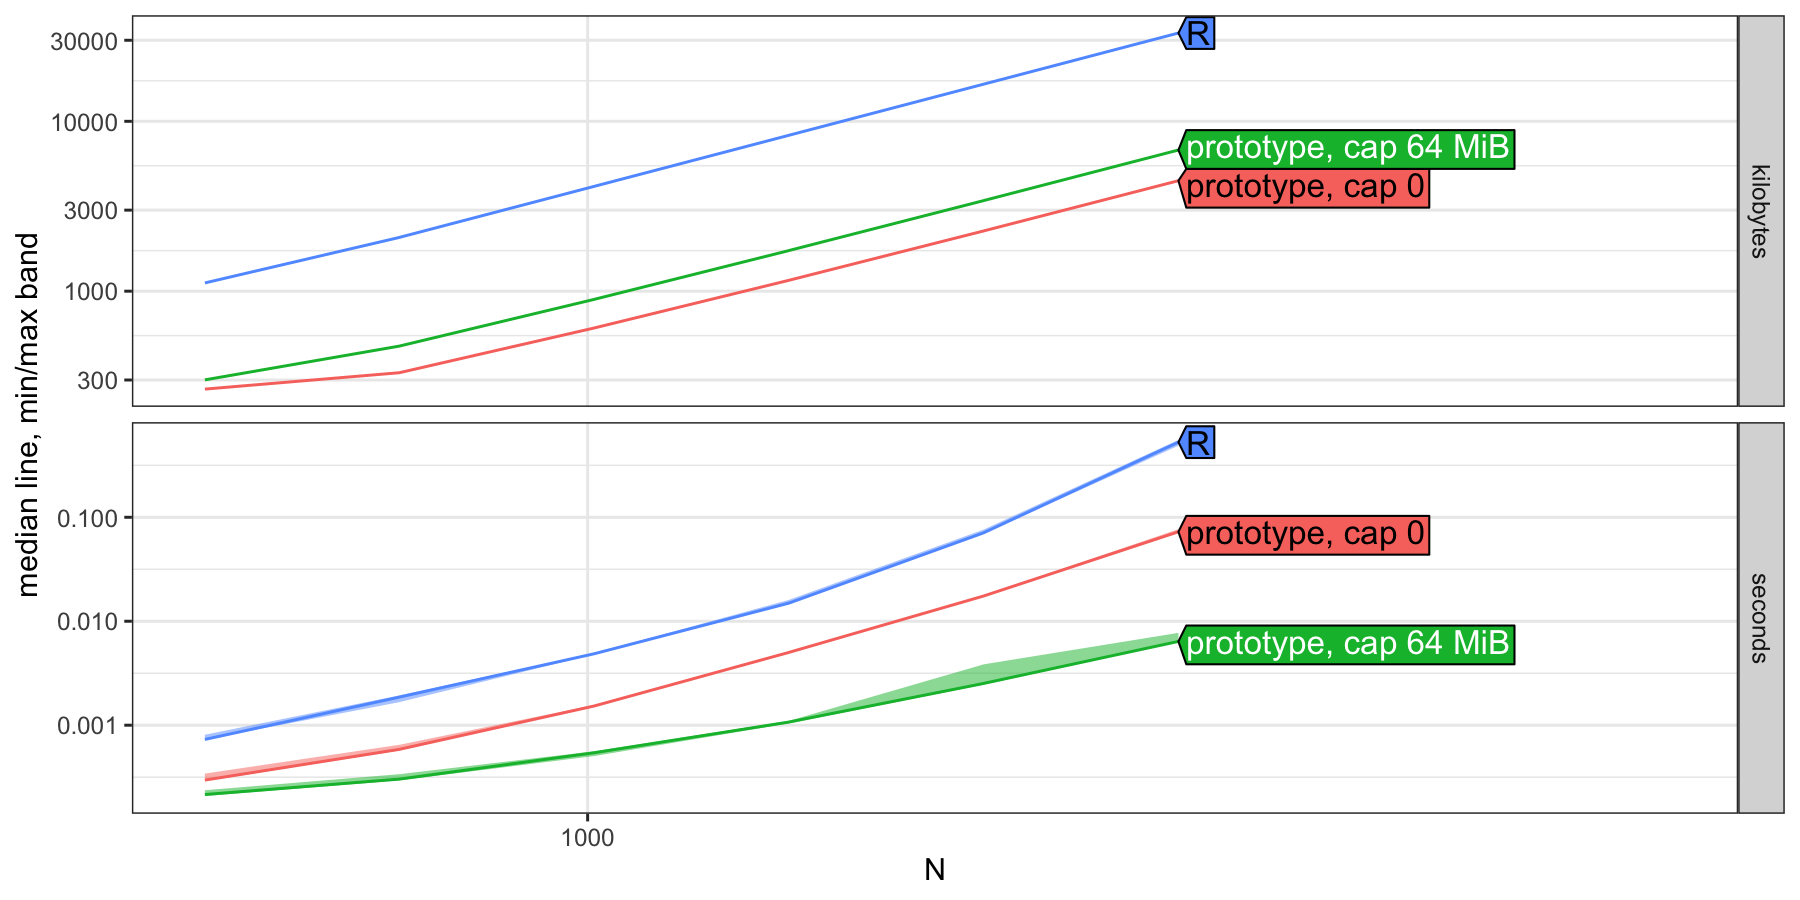

In [4]:
cap_0   <- built("exp_002_worst_case", "src-cap-0")
cap_64M <- built("exp_002_worst_case", "src")
cs <- list(span = 0.2, cell = 0.2)
spike <- atime(
  N = 2^(8:13),
  setup = { set.seed(20261110); data <- capture(fit_data(matrix(one_spike(N), N), 128, cs$span, cs$cell, rows = TRUE))$value },
  seconds.limit = 5, times = 5, check = TRUE,
  R = r_native_se(data$X, data$y, data$nd, cs),
  "prototype, cap 0" = native_se(cap_0, data$X, data$y, data$nd, cs, TRUE),
  "prototype, cap 64 MiB" = native_se(cap_64M, data$X, data$y, data$nd, cs, TRUE))
keep(spike, "exp_002")

## exp_003: the package source

`grid-cloud-3` from `tied.R`: half of the rows on a 6 by 6 by 6 grid, 15 point neighbourhoods.

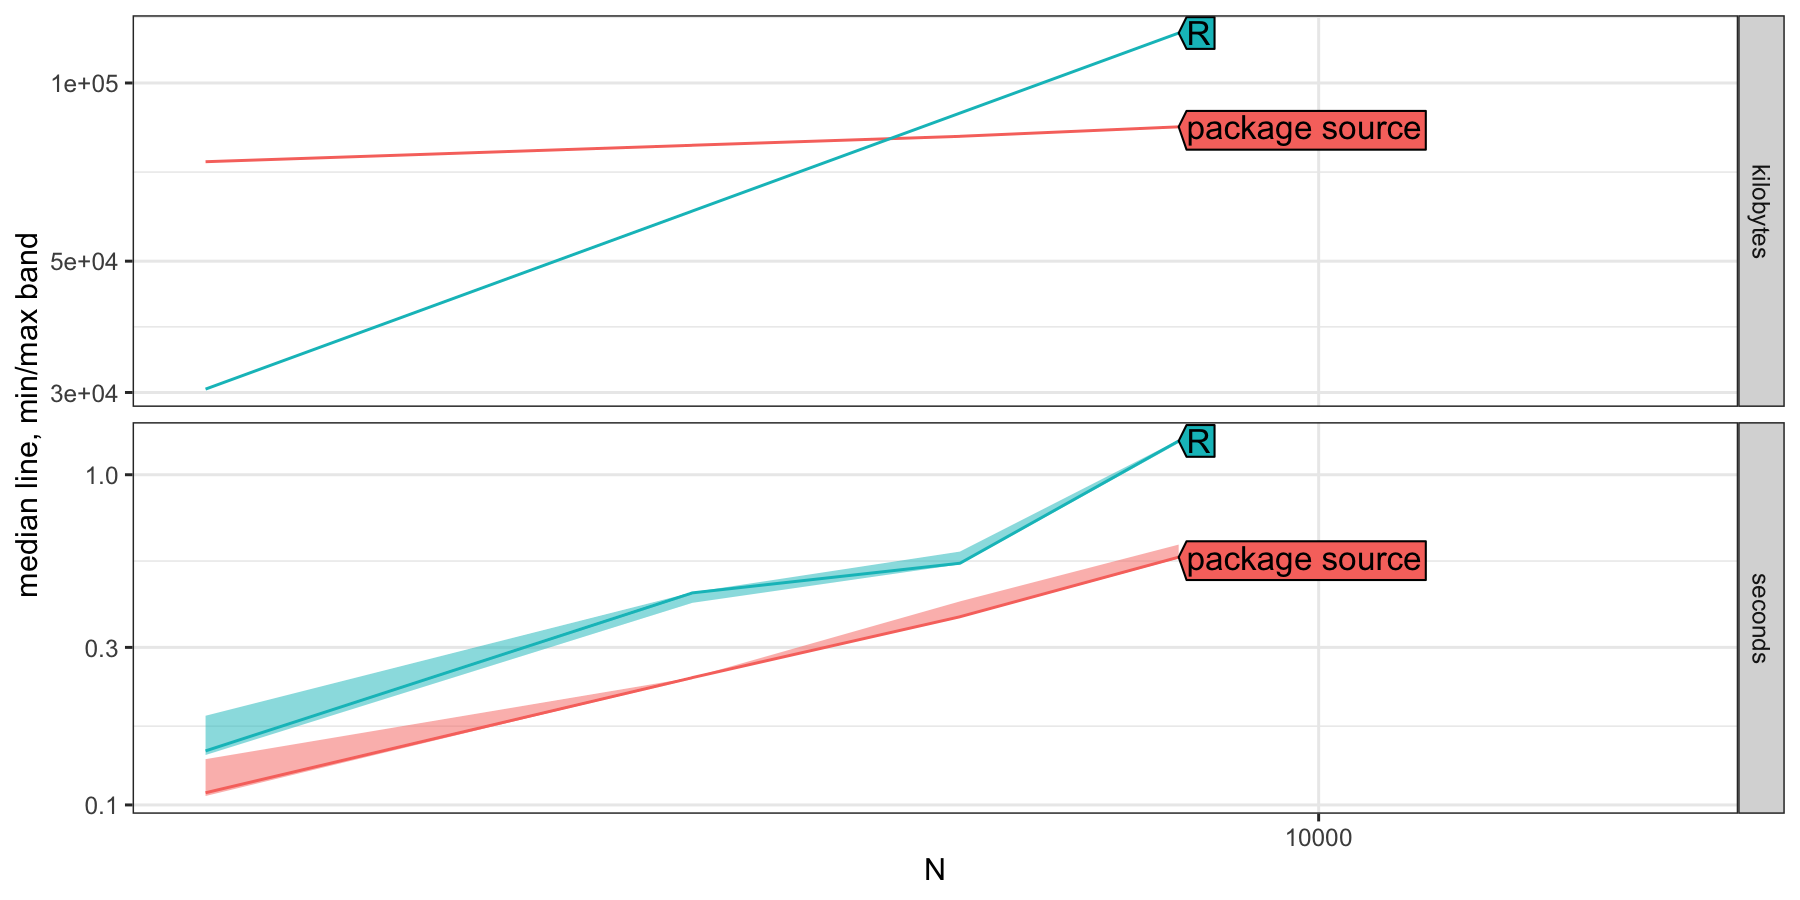

In [5]:
package <- built("exp_003_package_source", "src")
grid <- subset(measurement_cases(), id == "grid-cloud-3-8192")
tied <- atime(
  N = c(2048L, 4096L, 6000L, 8192L),
  setup = { cs <- transform(grid, n = N, span = 15.5 / N); input <- case_input(cs) },
  seconds.limit = 5, times = 3, check = TRUE,
  R = r_native_se(input$X, input$y, input$nd, cs),
  "package source" = native_se(package, input$X, input$y, input$nd, cs, TRUE))
keep(tied, "exp_003")

### the installed package against R

Toby's setup again. `identical` is bit for bit (`same`), seconds are user CPU (`speed.R`), MB is the memory requested (`memory.R`). the installed package has no probes, so its MB is read from the same source built with them.

In [6]:
probed <- built("exp_003_package_source", "probe-cap-67108864")
sizes <- c(500, 2000, 10000, 20000, 45000)
step <- progress(length(sizes))
do.call(rbind, lapply(seq_along(sizes), function(i) {
  n <- sizes[i]; step(i, sprintf("N = %d", n)); data <- toby_data(n)
  calls <- list(
    R        = function() predict(data$fit, data$nd, se = TRUE),
    nov6     = function() nov6$predict.loess(data$fit, data$nd, se = TRUE, cache = TRUE),
    loesslin = function() loesslin::predict_se(data$fit, data$nd),
    probed   = function() probed$predict.loess(data$fit, data$nd, se = TRUE))
  answers <- lapply(calls, function(call) call())
  seconds <- interleaved_seconds(calls[1:3], rounds = 3L)
  data.frame(N = n, identical = all(sapply(answers, same, answers$R)),
    R_seconds = seconds[["R"]], nov6_seconds = seconds[["nov6"]], loesslin_seconds = seconds[["loesslin"]],
    R_MB = reference_bytes(1, n, 80, 0.5, 2, 0)[["native"]] / 1e6,
    nov6_MB = reference_bytes(1, n, 80, 0.5, 2, data$fit$kd$parameter[["nv"]])[["native"]] / 1e6,
    loesslin_MB = probe_values(probed)$native_bytes / 1e6)
}))

[1/5] |                        | N = 500, 00:00 elapsed


[2/5] |====                    | N = 2000, 00:00 elapsed, about 00:00 left


[3/5] |========                | N = 10000, 00:00 elapsed, about 00:00 left


[4/5] |============            | N = 20000, 00:04 elapsed, about 00:03 left


[5/5] |================        | N = 45000, 00:21 elapsed, about 00:05 left


N,identical,R_seconds,nov6_seconds,loesslin_seconds,R_MB,nov6_MB,loesslin_MB
<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
500,TRUE,0.001,0.001,0.001,2.5546,2.5886,0.231888
2000,TRUE,0.011,0.004,0.001,40.2166,40.3526,0.801888
10000,TRUE,1.056,0.024,0.005,1001.0806,1001.7606,3.841888
20000,TRUE,4.011,0.053,0.009,4002.1606,4003.5206,7.641888
45000,TRUE,20.224,0.134,0.035,20254.8606,20257.9206,17.141888


## exp_004: sparse retention

`grid-cloud-4` from `tied.R`: half of the rows on a 4 by 4 by 4 by 4 grid, 15 point neighbourhoods. a kept vertex stores its neighbourhood only, so every vertex fits under the cap.

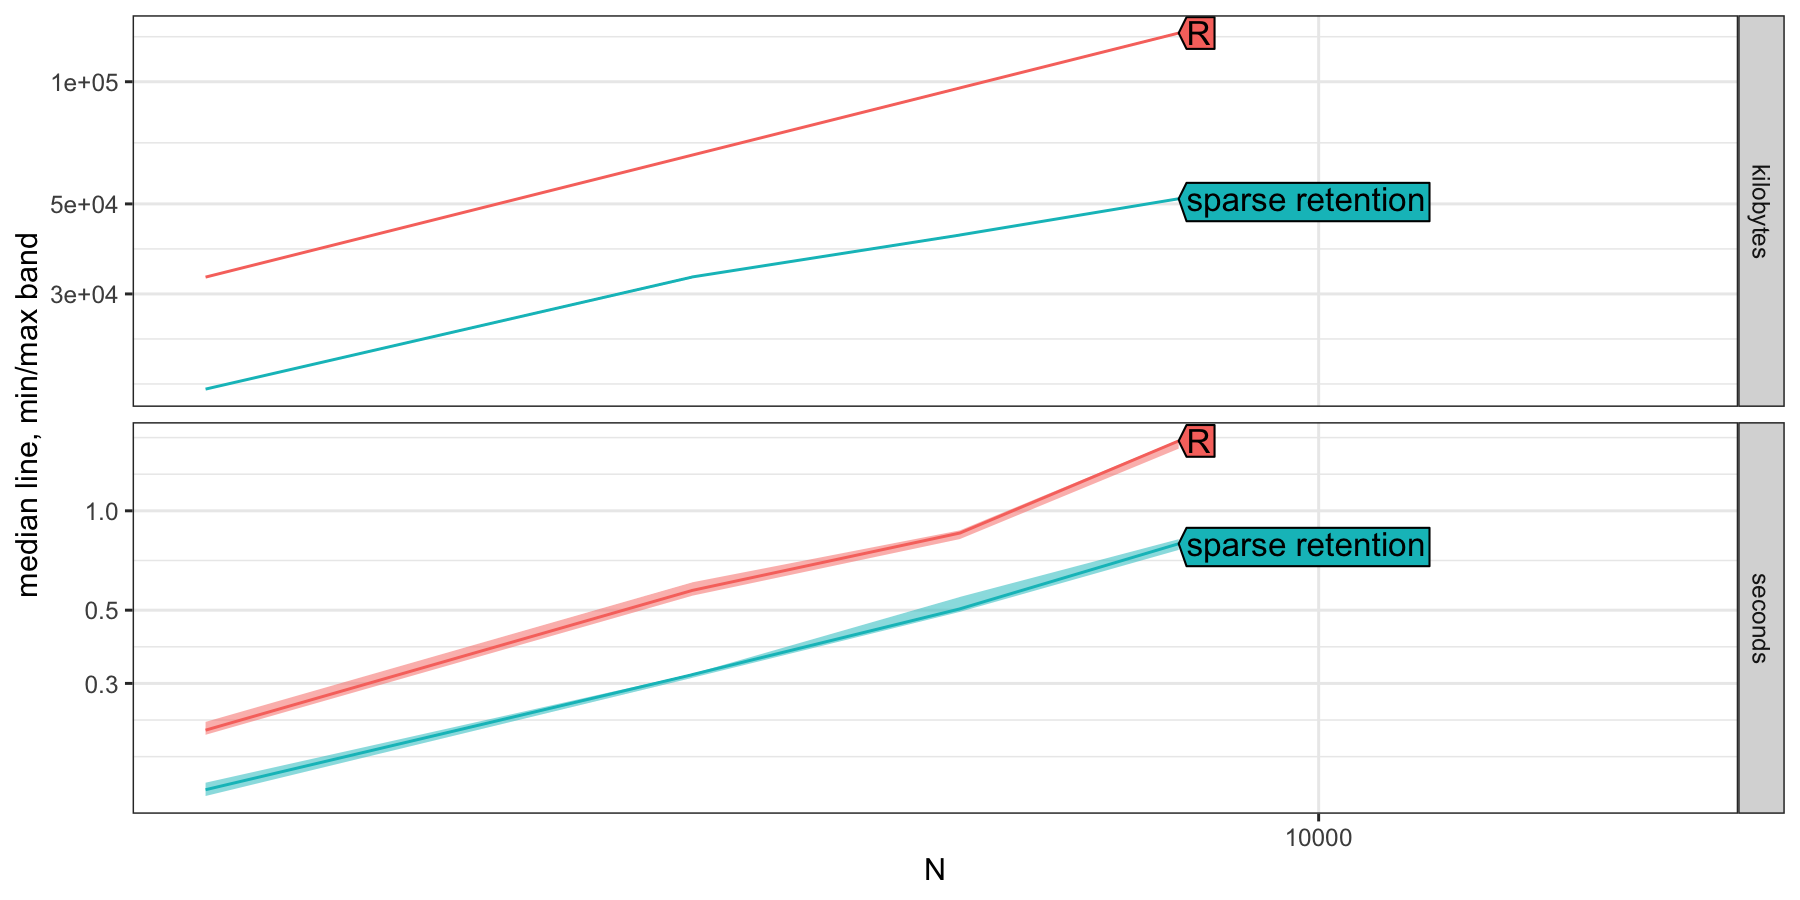

In [7]:
sparse <- built("exp_004_sparse_retention", "src")
grid <- subset(measurement_cases(), id == "grid-cloud-4-8192")
fewer <- atime(
  N = c(2048L, 4096L, 6000L, 8192L),
  setup = { cs <- transform(grid, n = N, span = 15.5 / N); input <- case_input(cs) },
  seconds.limit = 5, times = 5, check = TRUE,
  R = r_native_se(input$X, input$y, input$nd, cs),
  "sparse retention" = native_se(sparse, input$X, input$y, input$nd, cs, TRUE))
keep(fewer, "exp_004")